# 07 · NYC DOT Traffic Speeds – the Ida night vs a normal Wednesday

**Utility for the City Brain: high** · Domain: traffic · Incident types: `traffic_jam`

> Speeds on 137 monitored NYC road links every ~5 min: how a flood turns into a city-wide traffic jam, link by link and hour by hour.

| | |
|---|---|
| **Source** | NYC Open Data, DOT Traffic Speeds `i4gi-tjb9` |
| **Licence** | NYC Open Data, open |
| **In this repo** | Full extract: `data/traffic/nyc-dot-speeds/speed_ida.csv` (1 Sep 12:00 – 2 Sep 12:00 2021), `speed_ref.csv` (25–26 Aug, same hours) |
| **Get it** | https://data.cityofnewyork.us/resource/i4gi-tjb9.csv |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

| Column | Meaning |
|---|---|
| `speed` | Average speed on the link (mph) |
| `travel_time` | Seconds to cross the link |
| `data_as_of` | Timestamp of the reading (local time) |
| `link_id`, `link_name`, `borough` | Which road segment (highways, bridges, tunnels, arterials) |

In [2]:
def load(f, start):
    x = pd.read_csv(path(f'traffic/nyc-dot-speeds/{f}'), parse_dates=['data_as_of'])
    x['h'] = ((x.data_as_of - pd.Timestamp(start)) / pd.Timedelta('1h')).astype(int)   # hours since 12:00
    return x
ida = load('speed_ida.csv', '2021-09-01 12:00'); ref = load('speed_ref.csv', '2021-08-25 12:00')
print(f"Ida: {len(ida):,} readings on {ida.link_id.nunique()} links · reference: {len(ref):,}")
ida.head()

Ida: 35,835 readings on 137 links · reference: 39,319


,speed,travel_time,data_as_of,link_id,borough,link_name,h
0,14.29,387,2021-09-02 11:54:10,4616192,Staten Island,SIE E CLOVE ROAD - FINGERBOARD ROAD,23
1,14.29,462,2021-09-02 11:54:10,4616193,Staten Island,SIE E BRADLEY AVENUE - CLOVE ROAD,23
2,42.87,37,2021-09-02 11:54:10,4616194,Staten Island,SIE E WOOLEY AVENUE - BRADLEY AVENUE,23
3,42.87,91,2021-09-02 11:54:10,4616195,Staten Island,SIE E RICHMOND AVENUE - WOOLEY AVENUE,23
4,0.00,0,2021-09-02 11:54:10,4616196,Staten Island,MLK S - SIE E WALKER STREET - WOOLEY AVENUE,23


## 2. Speed relative to the same hour of a normal day

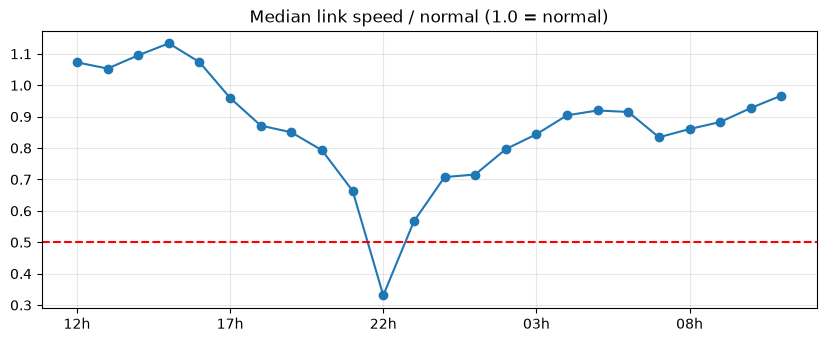

,median,links_below_half,links
16h,1.07,3,126
17h,0.96,4,126
18h,0.87,5,124
19h,0.85,6,124
20h,0.79,8,124
21h,0.66,33,124
22h,0.33,73,121
23h,0.57,58,119
00h,0.71,52,121
01h,0.72,51,119


In [3]:
a = ida.groupby(['link_id', 'h']).speed.median(); b = ref.groupby(['link_id', 'h']).speed.median()
r = (a / b.replace(0, np.nan)).dropna().rename('ratio').reset_index()
by_h = r.groupby('h').ratio.agg(median='median', links_below_half=lambda s: (s < .5).sum(), links='size')
by_h.index = [f"{(12 + h) % 24:02d}h" for h in by_h.index]
ax = by_h['median'].plot(marker='o', title='Median link speed / normal (1.0 = normal)'); ax.axhline(.5, ls='--', c='r'); plt.show()
by_h.round(2).iloc[4:16]

In [4]:
z = ida.assign(zero=ida.speed == 0).groupby('link_name').zero.agg(['mean', 'sum'])
print('Links that read 0 mph all the time (stuck / faulty feed):', int((z['mean'] > .95).sum()))
lin = ida[ida.link_name.str.contains('LINCOLN|Lincoln|LT ', regex=True) & (ida.speed == 0)]
print('Lincoln Tunnel links reading 0 mph (closure during the storm):')
lin.groupby('link_name').data_as_of.agg(first_zero='min', last_zero='max', readings='size')

Links that read 0 mph all the time (stuck / faulty feed): 5
Lincoln Tunnel links reading 0 mph (closure during the storm):


,first_zero,last_zero,readings
link_name,,,
LINCOLN TUNNEL E CENTER TUBE NJ - NY,2021-09-01 13:43:07,2021-09-02 07:13:07,166
LINCOLN TUNNEL E SOUTH TUBE - NJ - NY,2021-09-01 12:12:07,2021-09-02 11:54:05,109
LINCOLN TUNNEL W CENTER TUBE NY - NJ,2021-09-01 22:33:07,2021-09-02 11:49:07,113
LINCOLN TUNNEL W NORTH TUBE NY - NJ,2021-09-02 00:06:04,2021-09-02 02:04:03,5


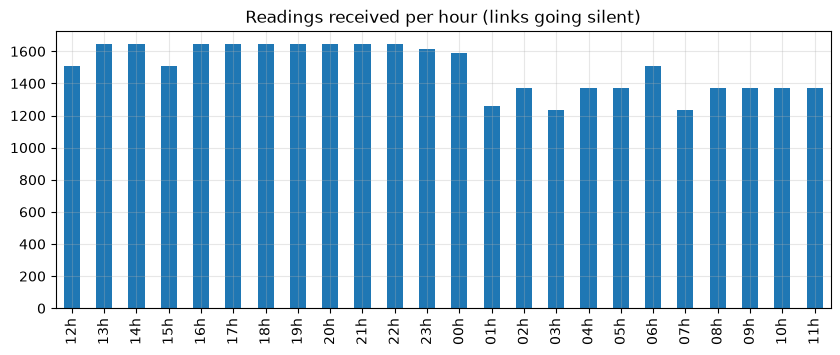

In [5]:
per_h = ida.groupby('h').size(); per_h.index = [f"{(12 + h) % 24:02d}h" for h in per_h.index]
per_h.plot(kind='bar', title='Readings received per hour (links going silent)'); plt.show()

## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Scenarios** | Real flood → traffic impact: at 22h the median link runs at about a third of its normal speed and most links are below half. 22h is also the peak of 311 flood calls (notebook 05) |
| **Detect** | **Speed 0 is ambiguous**: the Lincoln Tunnel read 0 for hours (closed, not jammed). Check context and neighbours. Links going silent during the storm: silence is not an incident |
| **Graph** | Link → borough → zone; a jam on many neighbouring links at once = one area-wide `traffic_jam` linked to the flood (`/chain`) |
| **Mock** | Real speed curves for `traffic_speed` sensors during the Storm-night scenario |

**Limits:** ~137 links only (mostly highways); mph; some links report irregularly.